# Overview
> **Chuyển đổi từ `3. CNN + LSTM/MNIST_CNN_LSTM.ipynb` sang PyTorch**
- Input: Chuỗi tối đa `maxToAdd = 8` ảnh chữ số MNIST 28x28.
- Output: Dự đoán tổng giá trị số học của chuỗi chữ số (MAE Loss).


In [1]:
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

np.random.seed(2018)
torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


# (1) Data (Tạo chuỗi từ dữ liệu MNIST thật)


In [2]:
with np.load(Path('../../data/mnist.npz')) as f:
    X_train_raw, y_train_temp = f['x_train'][:8000].astype('float32') / 255.0, f['y_train'][:8000]
    X_test_raw, y_test_temp = f['x_test'][:2000].astype('float32') / 255.0, f['y_test'][:2000]

maxToAdd = 8 if torch.cuda.is_available() else 5
def build_sum_seqs(X_raw, y_raw, n_seqs):
    x_seq = np.zeros((n_seqs, maxToAdd, 1, 28, 28), dtype=np.float32)
    y_seq = np.zeros((n_seqs,), dtype=np.float32)
    for i in range(n_seqs):
        numToAdd = int(np.ceil(np.random.rand() * maxToAdd))
        indices = np.random.choice(len(X_raw), size=numToAdd)
        x_seq[i, :numToAdd, 0] = X_raw[indices]
        y_seq[i] = float(np.sum(y_raw[indices]))
    return x_seq, y_seq

n_tr_seq = 2400 if torch.cuda.is_available() else 400
n_te_seq = 600 if torch.cuda.is_available() else 120
x_train, y_train = build_sum_seqs(X_train_raw, y_train_temp, n_tr_seq)
x_test, y_test = build_sum_seqs(X_test_raw, y_test_temp, n_te_seq)
train_loader = DataLoader(TensorDataset(torch.tensor(x_train), torch.tensor(y_train)), batch_size=64, shuffle=True)
test_loader = DataLoader(TensorDataset(torch.tensor(x_test), torch.tensor(y_test)), batch_size=64, shuffle=False)
print('x_train:', x_train.shape, '| y_train:', y_train.shape)


x_train: (400, 5, 1, 28, 28) | y_train: (400,)


# (2) Declare model (`MNIST_CNN_LSTM` với Batch Folding thay cho `TimeDistributed`)


In [3]:
class MNIST_CNN_LSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.cnn_encoder = nn.Sequential(
            nn.Conv2d(1, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2), nn.Dropout2d(0.2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2), nn.Dropout2d(0.2),
            nn.Conv2d(128, 256, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2), nn.Dropout2d(0.2),
            nn.Flatten()
        )
        self.lstm1 = nn.LSTM(256 * 3 * 3, 128, batch_first=True)
        self.lstm2 = nn.LSTM(128, 128, batch_first=True)
        self.drop = nn.Dropout(0.22)
        self.head = nn.Linear(128, 1)

    def forward(self, x):
        B, T, C, H, W = x.shape
        feats = self.cnn_encoder(x.reshape(B * T, C, H, W)).view(B, T, -1)
        out1, _ = self.lstm1(feats)
        _, (hn2, _) = self.lstm2(out1)
        return self.head(self.drop(hn2[-1])).squeeze(-1)

model = MNIST_CNN_LSTM().to(device)
print('Params:', sum(p.numel() for p in model.parameters() if p.requires_grad))


Params: 1748097


# (3) Train & (4) Evaluate (MAE Loss)


Epoch 01 | Test MAE: 10.140


Epoch 03 | Test MAE: 6.940


Epoch 06 | Test MAE: 6.060


Epoch 10 | Test MAE: 5.992
Training time: 103.99 s


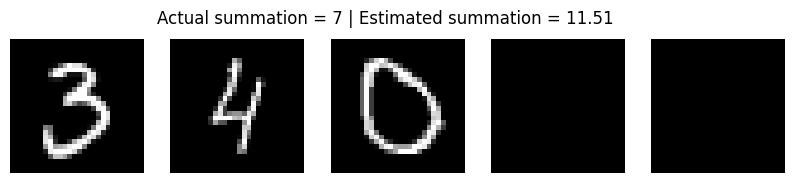

In [4]:
criterion = nn.L1Loss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
t0 = time.time()
for epoch in range(1, 11):
    model.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad(); loss = criterion(model(xb), yb); loss.backward(); optimizer.step()
    model.eval()
    val_mae = 0.0
    with torch.no_grad():
        for xb, yb in test_loader:
            val_mae += criterion(model(xb.to(device)), yb.to(device)).item() * len(xb)
    val_mae /= len(x_test)
    if epoch in [1, 3, 6, 10]:
        print(f'Epoch {epoch:02d} | Test MAE: {val_mae:.3f}')
print('Training time: %.2f s' % (time.time() - t0))

idx = np.random.choice(len(x_test))
plt.figure(figsize=(10, 2))
for k in range(maxToAdd):
    plt.subplot(1, maxToAdd, k + 1); plt.axis('off'); plt.imshow(x_test[idx, k, 0], cmap='gray')
with torch.no_grad():
    est = model(torch.tensor(x_test[idx:idx+1]).to(device)).item()
plt.suptitle(f'Actual summation = {int(y_test[idx])} | Estimated summation = {est:.2f}')
plt.show()
